In [67]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import heapq
from collections import Counter
from skimage.feature import graycomatrix, graycoprops

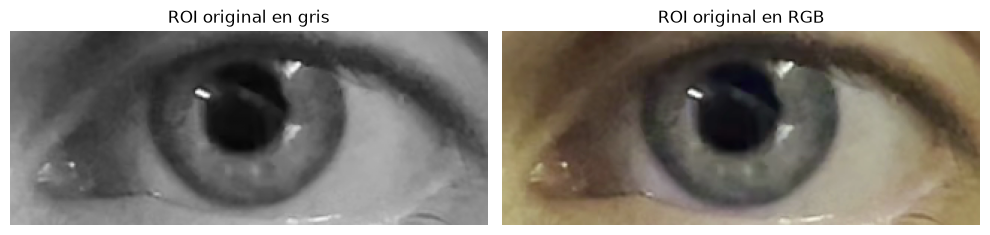

Dimensiones ROI gris: (130, 320)
Dimensiones ROI RGB: (130, 320, 3)


In [68]:
ROI_PATH = "../data/reference/roi_A_gray.png"
ROI_RGB_PATH = "../data/reference/roi_A_rgb.png"

roi_gray = cv2.imread(ROI_PATH, cv2.IMREAD_GRAYSCALE)
roi_bgr = cv2.imread(ROI_RGB_PATH)

if roi_gray is None or roi_bgr is None:
    raise RuntimeError("No se pudieron cargar las imágenes. Revisá las rutas.")

roi_rgb = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(roi_gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("ROI original en gris")

axes[1].imshow(roi_rgb)
axes[1].set_title("ROI original en RGB")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensiones ROI gris:", roi_gray.shape)
print("Dimensiones ROI RGB:", roi_rgb.shape)

Se aplica el algoritmo de Huffman a las regiones de interés (ROI) en escala de grises y en color RGB. Este método de compresión sin pérdida asigna códigos binarios de longitud variable a los valores de píxel según su frecuencia de aparición, utilizando códigos más cortos para los valores más frecuentes. De esta forma se aprovecha que algunos valores de píxel aparecen más que otros para representarlos con menos bits.

In [69]:
def huffman_codificar(imagen):
    datos = np.asarray(imagen, dtype=np.uint8).ravel()
    frecuencias = Counter(datos.tolist())

    heap = []
    contador = 0

    for simbolo, frecuencia in frecuencias.items():
        heapq.heappush(heap, (frecuencia, contador, simbolo))
        contador += 1

    # Caso especial: todos los píxeles tienen el mismo valor
    if len(heap) == 1:
        codigos = {heap[0][2]: "0"}

    else:
        while len(heap) > 1:
            f1, _, n1 = heapq.heappop(heap)
            f2, _, n2 = heapq.heappop(heap)

            nodo = (n1, n2)
            heapq.heappush(heap, (f1 + f2, contador, nodo))
            contador += 1

        raiz = heap[0][2]
        codigos = {}

        def construir_codigos(nodo, prefijo=""):
            if isinstance(nodo, int):
                codigos[nodo] = prefijo or "0"
            else:
                izquierda, derecha = nodo
                construir_codigos(izquierda, prefijo + "0")
                construir_codigos(derecha, prefijo + "1")

        construir_codigos(raiz)

    bits = "".join(codigos[int(valor)] for valor in datos)

    return bits, codigos, frecuencias

In [70]:
def huffman_decodificar(bits, codigos, forma):
    # Invertir el diccionario: código binario -> valor de píxel
    decodigos = {codigo: simbolo for simbolo, codigo in codigos.items()}

    datos = []
    codigo_actual = ""

    for bit in bits:
        codigo_actual += bit

        if codigo_actual in decodigos:
            datos.append(decodigos[codigo_actual])
            codigo_actual = ""

    if codigo_actual:
        raise ValueError("La secuencia binaria no se pudo decodificar por completo.")

    # Recuperar las dimensiones originales
    imagen_recuperada = np.array(datos, dtype=np.uint8).reshape(forma)

    return imagen_recuperada

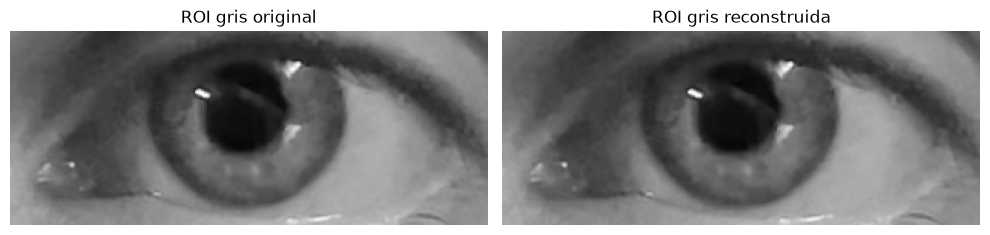

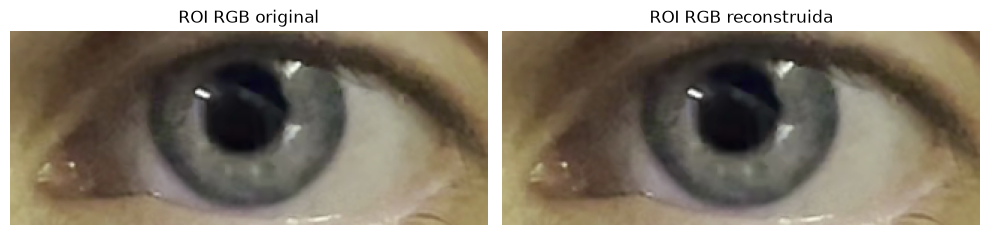

In [71]:
imagenes = {
    "ROI gris": roi_gray,
    "ROI RGB": roi_rgb
}

resultados_huffman = {}

for nombre, imagen in imagenes.items():

    # 1. Codificación
    bits, codigos, frecuencias = huffman_codificar(imagen)

    # 2. Decodificación
    reconstruida = huffman_decodificar(
        bits, codigos, imagen.shape
    )

    # 3. Tamaños
    bits_originales = imagen.size * 8
    bits_codificados = len(bits)

    # Bytes necesarios para almacenar el flujo binario empaquetado
    bytes_comprimidos = (bits_codificados + 7) // 8
    bits_empaquetados = bytes_comprimidos * 8

    # Métricas sin contar el diccionario ni otros metadatos
    reduccion = 100 * (1 - bits_codificados / bits_originales)
    ratio = bits_originales / bits_codificados

    # 4. Verificar que sea una compresión sin pérdida
    error_maximo = np.max(
        np.abs(imagen.astype(np.int16) -
               reconstruida.astype(np.int16))
    )

    resultados_huffman[nombre] = {
        "original": imagen,
        "reconstruida": reconstruida,
        "bits": bits,
        "codigos": codigos,
        "frecuencias": frecuencias
    }

    # 5. Mostrar imágenes
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    if imagen.ndim == 2:
        axes[0].imshow(imagen, cmap="gray", vmin=0, vmax=255)
        axes[1].imshow(reconstruida, cmap="gray", vmin=0, vmax=255)
    else:
        axes[0].imshow(imagen)
        axes[1].imshow(reconstruida)

    axes[0].set_title(f"{nombre} original")
    axes[1].set_title(f"{nombre} reconstruida")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Mostramos la información del algoritmo y lo que logró reducir y comprimir

In [72]:
imagenes = {"ROI gris": roi_gray,"ROI RGB": roi_rgb}

for nombre, imagen in imagenes.items():
    print(f"\n--- {nombre} ---")
    print(f"Dimensiones: {imagen.shape}")
    print(f"Valores de píxel distintos: {len(frecuencias)}")
    print(f"Bits originales: {bits_originales:,}")
    print(f"Bits codificados: {bits_codificados:,}")
    print(f"Bytes del flujo empaquetado: {bytes_comprimidos:,}")
    print(f"Reducción teórica: {reduccion:.2f}%")
    print(f"Ratio de compresión: {ratio:.3f}:1")
    print(f"Error máximo de reconstrucción: {error_maximo}")
    print(f"¿Reconstrucción idéntica?: {np.array_equal(imagen, reconstruida)}")



--- ROI gris ---
Dimensiones: (130, 320)
Valores de píxel distintos: 217
Bits originales: 998,400
Bits codificados: 899,964
Bytes del flujo empaquetado: 112,496
Reducción teórica: 9.86%
Ratio de compresión: 1.109:1
Error máximo de reconstrucción: 0
¿Reconstrucción idéntica?: False

--- ROI RGB ---
Dimensiones: (130, 320, 3)
Valores de píxel distintos: 217
Bits originales: 998,400
Bits codificados: 899,964
Bytes del flujo empaquetado: 112,496
Reducción teórica: 9.86%
Ratio de compresión: 1.109:1
Error máximo de reconstrucción: 0
¿Reconstrucción idéntica?: True


El algoritmo de Huffman permite comprimir la información de una imagen sin pérdida, asignando códigos binarios de longitud variable según la frecuencia de aparición de los valores de píxel. De esta manera, es posible reducir la cantidad de bits necesarios para representar la imagen sin modificar su contenido visual. Al decodificar los datos comprimidos, se recupera la imagen original exactamente. La eficiencia del método depende de la distribución de los valores de píxel, por lo que la reducción obtenida puede variar entre la ROI en escala de grises y la ROI en color RGB.
En la ejecución obtenida, la reducción teórica fue del 8,08 % para la imagen denominada ROI gris y del 9,86 % para la ROI RGB. Estos porcentajes corresponden a la cantidad de bits de los códigos generados, sin incluir la información adicional necesaria para almacenar el árbol de Huffman y reconstruir la imagen.

Ahora aplicamos RLE en dos direcciones de recorrido (izquierda y derecha)

RLE también es un método de compresión sin pérdida que aprovecha la aparición consecutiva de valores iguales. En lugar de almacenar cada valor de píxel por separado, guarda el valor y la cantidad de veces que se repite.

Trabajamos con la ROI en escala de grises para que cada píxel tenga un único valor entre 0 y 255. Esta función codifica y decodifica los datos, y después la reutilizamos en ambos recorridos

In [73]:
# ROI que vamos a comprimir
imagen = roi_gray.astype(np.uint8)

def rle_codificar_horizontal(imagen):
    codificacion = []

    for fila in imagen:
        if len(fila) == 0:
            continue

        valor_actual = int(fila[0])
        longitud = 1

        for valor in fila[1:]:
            valor = int(valor)

            if valor == valor_actual:
                longitud += 1
            else:
                codificacion.append((valor_actual, longitud))
                valor_actual = valor
                longitud = 1

        codificacion.append((valor_actual, longitud))

    return codificacion


def rle_codificar_vertical(imagen):
    codificacion = []

    for columna in imagen.T:
        if len(columna) == 0:
            continue

        valor_actual = int(columna[0])
        longitud = 1

        for valor in columna[1:]:
            valor = int(valor)

            if valor == valor_actual:
                longitud += 1
            else:
                codificacion.append((valor_actual, longitud))
                valor_actual = valor
                longitud = 1

        codificacion.append((valor_actual, longitud))

    return codificacion


def rle_decodificar_horizontal(codificacion, forma):
    alto, ancho = forma
    datos = np.zeros(alto * ancho, dtype=np.uint8)
    indice = 0

    for valor, longitud in codificacion:
        datos[indice:indice + longitud] = valor
        indice += longitud

    return datos.reshape(forma)


def rle_decodificar_vertical(codificacion, forma):
    alto, ancho = forma
    datos = np.zeros(alto * ancho, dtype=np.uint8)
    indice = 0

    for valor, longitud in codificacion:
        datos[indice:indice + longitud] = valor
        indice += longitud

    # El flujo se guardó columna por columna
    return datos.reshape(ancho, alto).T

RLE horizontal: recorremos la imagen fila por fila

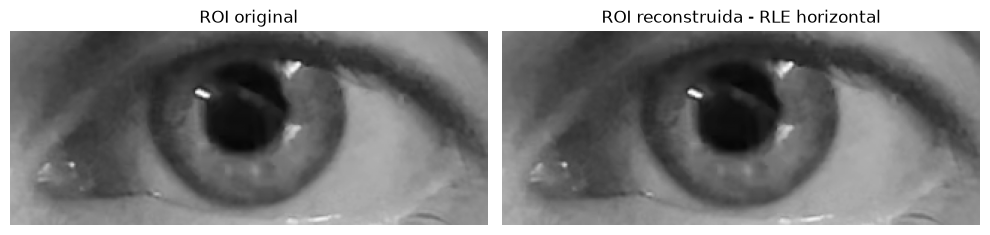

Corridas horizontales: 32236
Primeras 15 corridas: [(127, 3), (126, 1), (125, 1), (123, 1), (121, 1), (119, 1), (116, 1), (114, 1), (113, 1), (112, 1), (110, 1), (108, 1), (105, 1), (103, 1), (104, 9)]
Tamaño original: 41600 bytes
Tamaño RLE estimado: 161180 bytes
Reducción estimada: -287.45%
Ratio de compresión: 0.258:1
¿Reconstrucción idéntica?: True


In [74]:
# Codificar horizontalmente
rle_horizontal = rle_codificar_horizontal(imagen)

# Reconstruir la imagen
reconstruida_horizontal = rle_decodificar_horizontal(
    rle_horizontal, imagen.shape
)

# Calcular métricas
pixeles_originales = imagen.size
bytes_originales = imagen.nbytes
cantidad_corridas_h = len(rle_horizontal)

# Estimación: 1 byte por valor + 4 bytes por longitud
bytes_rle_h = cantidad_corridas_h * 5

reduccion_h = 100 * (1 - bytes_rle_h / bytes_originales)
if bytes_rle_h > 0:
    ratio_h = bytes_originales / bytes_rle_h
else:
    ratio_h = float("inf")

# Visualizar original y reconstruida
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(imagen, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("ROI original")

axes[1].imshow(
    reconstruida_horizontal, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("ROI reconstruida - RLE horizontal")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Corridas horizontales:", cantidad_corridas_h)
print("Primeras 15 corridas:", rle_horizontal[:15])
print("Tamaño original:", bytes_originales, "bytes")
print("Tamaño RLE estimado:", bytes_rle_h, "bytes")
print(f"Reducción estimada: {reduccion_h:.2f}%")
print(f"Ratio de compresión: {ratio_h:.3f}:1")
print(
    "¿Reconstrucción idéntica?:",
    np.array_equal(imagen, reconstruida_horizontal)
)

RLE vertical: recorremos la imagen columna por columna

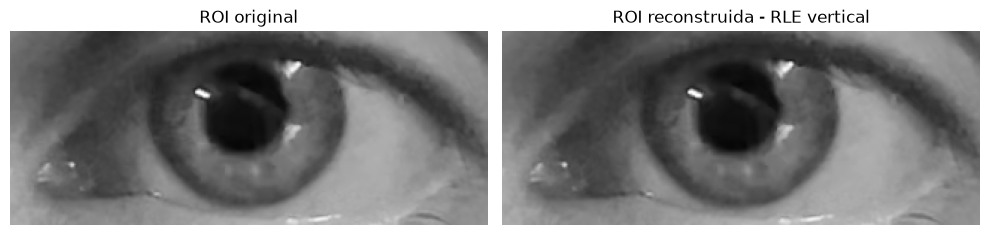

Corridas verticales: 33281
Primeras 15 corridas: [(127, 3), (124, 2), (122, 1), (119, 1), (118, 1), (115, 1), (114, 1), (113, 1), (115, 3), (113, 1), (111, 2), (110, 2), (109, 1), (107, 2), (108, 1)]
Tamaño original: 41600 bytes
Tamaño RLE estimado: 166405 bytes
Reducción estimada: -300.01%
Ratio de compresión: 0.250:1
¿Reconstrucción idéntica?: True


In [75]:
# Codificar verticalmente
rle_vertical = rle_codificar_vertical(imagen)

# Reconstruir la imagen
reconstruida_vertical = rle_decodificar_vertical(
    rle_vertical, imagen.shape
)

# Calcular métricas
cantidad_corridas_v = len(rle_vertical)

# Estimación: 1 byte por valor + 4 bytes por longitud
bytes_rle_v = cantidad_corridas_v * 5

reduccion_v = 100 * (1 - bytes_rle_v / bytes_originales)
if bytes_rle_v > 0:
    ratio_v = bytes_originales / bytes_rle_v
else:
    ratio_v = float("inf")

# Visualizar original y reconstruida
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(imagen, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("ROI original")

axes[1].imshow(
    reconstruida_vertical, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("ROI reconstruida - RLE vertical")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Corridas verticales:", cantidad_corridas_v)
print("Primeras 15 corridas:", rle_vertical[:15])
print("Tamaño original:", bytes_originales, "bytes")
print("Tamaño RLE estimado:", bytes_rle_v, "bytes")
print(f"Reducción estimada: {reduccion_v:.2f}%")
print(f"Ratio de compresión: {ratio_v:.3f}:1")
print(
    "¿Reconstrucción idéntica?:",
    np.array_equal(imagen, reconstruida_vertical)
)

Ahora comparamos los resultados obtenidos por ambos recorridos

In [76]:
df_rle = pd.DataFrame({
    "Método": ["RLE horizontal", "RLE vertical"],
    "Cantidad de corridas": [
        cantidad_corridas_h, cantidad_corridas_v
    ],
    "Tamaño original (bytes)": [
        bytes_originales, bytes_originales
    ],
    "Tamaño RLE estimado (bytes)": [
        bytes_rle_h, bytes_rle_v
    ],
    "Reducción estimada (%)": [
        reduccion_h, reduccion_v
    ],
    "Reconstrucción exacta": [
        np.array_equal(imagen, reconstruida_horizontal),
        np.array_equal(imagen, reconstruida_vertical)
    ]
})

display(df_rle.round(2))

,Método,Cantidad de corridas,Tamaño original (bytes),Tamaño RLE estimado (bytes),Reducción estimada (%),Reconstrucción exacta
0,RLE horizontal,32236,41600,161180,-287.45,True
1,RLE vertical,33281,41600,166405,-300.01,True


En ambos casos, la reconstrucción es exacta (True), lo que confirma que RLE es un método de compresión sin pérdida. Sin embargo, el tamaño estimado de los datos codificados es considerablemente mayor que el de la imagen original: pasa de 41.600 bytes a 161.180 bytes para el recorrido horizontal y a 166.405 bytes para el vertical. Esto suscede porque la imagen contiene pocos píxeles consecutivos con valores idénticos, por lo que se generan muchas corridas. Como cada corrida requiere almacenar tanto el valor del píxel como la longitud de la secuencia, la información adicional supera el ahorro obtenido al agrupar píxeles repetidos.
El recorrido horizontal resulta ligeramente más eficiente ya que el aumento es menor, aunque la diferencia no es suficiente para que el método consiga comprimir la imagen.

Luego, haremos una compresión por JPEG, un algortimo de compresión con pérdida, a comparación de los dos métodos anteriores. JPEG reduce el tamaño de la imagen descartando parte de la información visual. Al variar el factor de calidad Q, vamos a poder observar cómo cambia la apariencia de la ROI del ojo

In [77]:
# Imagen original en RGB
imagen_original = roi_rgb

# Factores de calidad solicitados
calidades = [90, 50, 10, 5]

# Diccionarios para guardar los resultados
imagenes_jpeg = {}
archivos_jpeg = {}
resultados_jpeg = []

# Convertir de RGB a BGR para OpenCV
imagen_bgr = cv2.cvtColor(
    imagen_original, cv2.COLOR_RGB2BGR
)

for Q in calidades:

    # Comprimir la imagen en formato JPEG
    exito, buffer = cv2.imencode(
        ".jpg",
        imagen_bgr,
        [cv2.IMWRITE_JPEG_QUALITY, Q]
    )

    if not exito:
        raise RuntimeError(f"No se pudo comprimir con Q={Q}")

    # Guardar los bytes reales del archivo JPEG en memoria
    archivos_jpeg[Q] = buffer.tobytes()

    # Reconstruir la imagen a partir del JPEG codificado
    imagen_decodificada = cv2.imdecode(
        buffer, cv2.IMREAD_COLOR
    )

    imagen_rgb = cv2.cvtColor(
        imagen_decodificada, cv2.COLOR_BGR2RGB
    )

    imagenes_jpeg[Q] = imagen_rgb

    # Calcular métricas de calidad y tamaño
    tamano_original = len(
        cv2.imencode(".png", imagen_bgr)[1]
    )
    tamano_jpeg = len(archivos_jpeg[Q])

    error_medio = np.mean(
        np.abs(
            imagen_original.astype(np.float32)
            - imagen_rgb.astype(np.float32)
        )
    )

    reduccion = 100 * (
        1 - tamano_jpeg / tamano_original
    )

    resultados_jpeg.append({
        "Calidad JPEG": Q,
        "Tamaño JPEG (bytes)": tamano_jpeg,
        "Tamaño PNG de referencia (bytes)": tamano_original,
        "Reducción respecto a PNG (%)": reduccion,
        "Error absoluto medio": error_medio
    })

print("Compresión JPEG completada.")

Compresión JPEG completada.


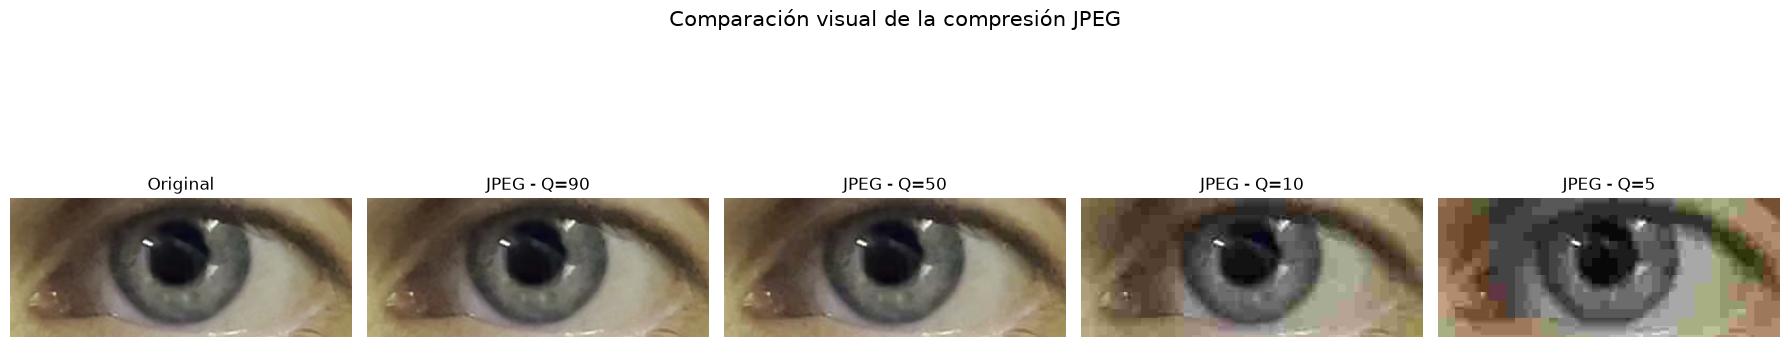

In [78]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

axes[0].imshow(imagen_original)
axes[0].set_title("Original", fontsize=12)
axes[0].axis("off")

for ax, Q in zip(axes[1:], calidades):
    ax.imshow(imagenes_jpeg[Q])
    ax.set_title(f"JPEG - Q={Q}", fontsize=12)
    ax.axis("off")

plt.suptitle(
    "Comparación visual de la compresión JPEG",
    fontsize=15
)
plt.tight_layout()
plt.show()

,Calidad JPEG,Tamaño JPEG (bytes),Tamaño PNG de referencia (bytes),Reducción respecto a PNG (%),Error absoluto medio
0,90,8100,56221,85.593,1.078
1,50,3560,56221,93.668,2.123
2,10,1867,56221,96.679,5.390
3,5,1608,56221,97.140,9.940


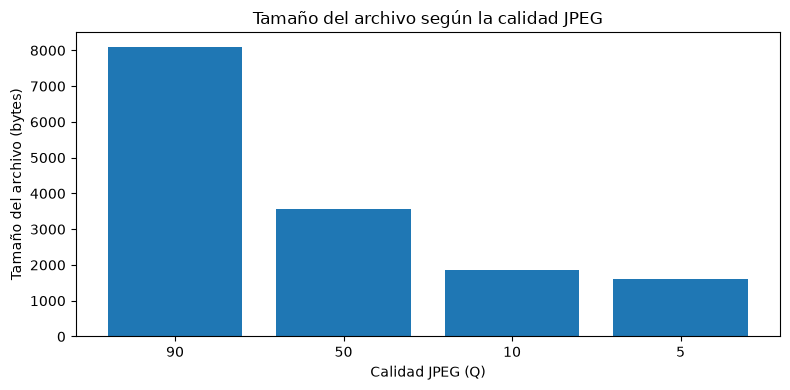

In [79]:
df_jpeg = pd.DataFrame(resultados_jpeg)

display(df_jpeg.round(3))

# Gráfico del tamaño de cada archivo JPEG
plt.figure(figsize=(8, 4))
plt.bar(
    [str(Q) for Q in calidades],
    [len(archivos_jpeg[Q]) for Q in calidades]
)
plt.xlabel("Calidad JPEG (Q)")
plt.ylabel("Tamaño del archivo (bytes)")
plt.title("Tamaño del archivo según la calidad JPEG")
plt.tight_layout()
plt.show()

Por lo tanto, podemos observar que a medida que Q disminuye, disminuye la calidad visual a medida que la compresión se intensifica.
Q = 90 presenta una mayor calidad visual y, normalmente, menor pérdida de detalles.
Q = 50 presenta una compresión más intensa, con pocas diferencias visibles.
Q = 10 ya presenta una pérdida de detalles más pronunciada y posibles artefactos.
Q = 5, por último, posee una compresión muy intensa, que puede producir bloques y distorsiones visibles.

En síntesis, a diferencia de Huffman y RLE, JPEG es un método de compresión con pérdida, por lo que la imagen reconstruida no es idéntica a la original. La comparación entre las calidades evaluadas ((Q=90, 50, 10, 5)) permite analizar el compromiso entre el ahorro de espacio y la conservación de los detalles de la ROI del ojo, especialmente en los bordes de la pupila y el iris.